## After restarting kernel
After any kernel restart, the cells that must run are:

The config cell (with those two imports now added)
The split cell, which defines build_manifest and loads the saved manifest
The training and evaluation code cell

## Setup and Config

In [3]:
from huggingface_hub import login
login()

In [10]:
import os, json, random, hashlib, copy, time
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import torch

SEED = 42
BASE = Path.home() / "plant_project"  #local, copy results to drive later
RAW_ROOT = BASE / "plants"  # reuses the images you already downloaded
SPLIT_CSV = BASE / "species_split.csv"
ROWS_JSON = BASE / "species_urls.json"
CKPT_DIR = BASE / "checkpoints"
RESULTS_DIR = BASE / "results"
for p in (BASE, RAW_ROOT, CKPT_DIR, RESULTS_DIR):
    p.mkdir(parents=True, exist_ok=True)
    
PER_SPECIES = 100
MIN_PER_CLASS = 30
random.seed(SEED); np.random.seed(SEED)

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
use_amp = device == "cuda"
print("device:", device, "| project folder:", BASE)

device: mps | project folder: /Users/zurimckee/plant_project


## List of Species and Availability Scan

Drafts list of everyday plants that should correlate with the class plant-picture dataset. Will be edited once the team agrees on species list.


In [6]:
CANDIDATES = [
    # houseplants
    "Epipremnum aureum", "Monstera deliciosa", "Dracaena trifasciata", "Chlorophytum comosum",
    "Spathiphyllum wallisii", "Aloe vera", "Crassula ovata", "Ficus elastica", "Ficus lyrata",
    "Zamioculcas zamiifolia", "Nephrolepis exaltata", "Hedera helix", "Tradescantia zebrina",
    "Dieffenbachia seguine", "Aglaonema commutatum", "Schlumbergera truncata",
    "Echeveria elegans", "Saintpaulia ionantha", "Philodendron hederaceum",
    # trees
    "Quercus robur", "Quercus alba", "Acer rubrum", "Acer saccharum", "Acer platanoides",
    "Betula pendula", "Pinus sylvestris", "Pinus strobus", "Fraxinus americana",
    "Liriodendron tulipifera", "Platanus occidentalis", "Ginkgo biloba", "Cornus florida",
    "Salix babylonica", "Magnolia grandiflora",
    # shrubs / common garden
    "Hydrangea macrophylla", "Buxus sempervirens", "Rhododendron ponticum", "Rosa canina",
    "Forsythia suspensa", "Syringa vulgaris", "Ilex aquifolium", "Taxus baccata",
    "Lavandula angustifolia", "Taraxacum officinale",
]
SCAN_LIMIT = 3_000_000   # rows to scan; lower it if this takes too long

The scan streams the HuggingFace dataset and reports how many images exist for each candidate in the scanned window, and saves URLs to Drive.

Names are matched on genus + species (first two words, case-insensitive). Counts are for the scanned sample, not the whole dataset. Houseplants may be thinly covered because GBIF is mostly wild observations.

In [8]:
from datasets import load_dataset

def norm(s):
    return " ".join(s.lower().split()[:2]) if s else ""

cand_norm = {norm(c): c for c in CANDIDATES}
ds = load_dataset("juppy44/gbif-plants-raw", split="train", streaming=True)
ds = ds.shuffle(seed=SEED, buffer_size=100_000)

counts, urls, seen = Counter(), defaultdict(list), 0
t0 = time.time()
for r in ds.take(SCAN_LIMIT):
    seen += 1
    key = cand_norm.get(norm(r["species_name"]))
    if key:
        counts[key] += 1
        if r["image_url"] and len(urls[key]) < PER_SPECIES:
            urls[key].append(r["image_url"])
    if seen % 500_000 == 0:
        print(f"scanned {seen:,} rows, {time.time()-t0:.0f}s")

report = pd.DataFrame({"species": CANDIDATES})
report["images_found"] = report.species.map(lambda s: counts.get(s, 0))
report["urls_saved"] = report.species.map(lambda s: len(urls.get(s, [])))
report["status"] = np.where(report.urls_saved >= PER_SPECIES, "ok",
                    np.where(report.urls_saved >= MIN_PER_CLASS, "thin", "need other source"))
print(report.sort_values("images_found").to_string(index=False))
report.to_csv(BASE / "species_availability.csv", index=False)
json.dump(urls, open(ROWS_JSON, "w"))
print("saved URLs ->", ROWS_JSON)

scanned 500,000 rows, 61s
scanned 1,000,000 rows, 84s
scanned 1,500,000 rows, 106s
scanned 2,000,000 rows, 128s
scanned 2,500,000 rows, 151s
scanned 3,000,000 rows, 173s
                species  images_found  urls_saved            status
   Saintpaulia ionantha             0           0 need other source
      Echeveria elegans             1           1 need other source
 Schlumbergera truncata             1           1 need other source
 Zamioculcas zamiifolia             1           1 need other source
 Spathiphyllum wallisii             6           6 need other source
   Aglaonema commutatum            10          10 need other source
           Ficus lyrata            11          11 need other source
 Lavandula angustifolia            21          21 need other source
   Nephrolepis exaltata            25          25 need other source
     Forsythia suspensa            30          30              thin
          Ginkgo biloba            36          36              thin
         Ficus

## Downloads images
reads URLs from Drive, so it survives runtime restarts



In [9]:
import requests
from concurrent.futures import ThreadPoolExecutor

rows = json.load(open(ROWS_JSON))

def grab(args):
    species, i, url = args
    d = RAW_ROOT / species.replace(" ", "_")
    d.mkdir(parents=True, exist_ok=True)
    path = d / f"{i}.jpg"
    if path.exists():
        return True
    for attempt in range(2):
        try:
            r = requests.get(url, timeout=10)
            r.raise_for_status()
            path.write_bytes(r.content)
            return True
        except Exception:
            time.sleep(1)
    return False

jobs = [(s, i, u) for s, us in rows.items() for i, u in enumerate(us) if u]
print(len(jobs), "images to download")
with ThreadPoolExecutor(16) as ex:
    results = list(ex.map(grab, jobs))
print(sum(results), "succeeded,", len(results) - sum(results), "failed")

3186 images to download
3176 succeeded, 10 failed


## Clean images
Removes small, corrupt, and duplicate images.

In [10]:
from PIL import Image

def clean_folder(root, min_side=64):
    root = Path(root)
    removed = Counter()
    seen_hashes = {}
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                w, h = im.size
            if min(w, h) < min_side:
                raise ValueError("too small")
        except Exception:
            p.unlink(); removed["corrupt_or_tiny"] += 1
            continue
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in seen_hashes:
            p.unlink(); removed["duplicate"] += 1
        else:
            seen_hashes[h] = p
    print("removed:", dict(removed))
    counts = {d.name: len([f for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"}])
              for d in root.iterdir() if d.is_dir()}
    for k, v in sorted(counts.items(), key=lambda x: x[1]):
        print(f"{v:4d}  {k}")
    return counts

species_counts = clean_folder(RAW_ROOT)

removed: {'duplicate': 4}
   1  Schlumbergera_truncata
   1  Echeveria_elegans
   1  Zamioculcas_zamiifolia
   6  Spathiphyllum_wallisii
  10  Aglaonema_commutatum
  11  Ficus_lyrata
  21  Lavandula_angustifolia
  23  Forsythia_suspensa
  25  Nephrolepis_exaltata
  36  Ginkgo_biloba
  44  Ficus_elastica
  55  Dracaena_trifasciata
  56  Hydrangea_macrophylla
  63  Salix_babylonica
  70  Aloe_vera
  72  Chlorophytum_comosum
  84  Philodendron_hederaceum
  97  Quercus_alba
  98  Cornus_florida
  99  Syringa_vulgaris
  99  Tradescantia_zebrina
 100  Fraxinus_americana
 100  Buxus_sempervirens
 100  Betula_pendula
 100  Pinus_sylvestris
 100  Quercus_robur
 100  Magnolia_grandiflora
 100  Liriodendron_tulipifera
 100  Taxus_baccata
 100  Monstera_deliciosa
 100  Platanus_occidentalis
 100  Acer_rubrum
 100  Rosa_canina
 100  Rhododendron_ponticum
 100  Acer_saccharum
 100  Epipremnum_aureum
 100  Hedera_helix
 100  Pinus_strobus
 100  Taraxacum_officinale
 100  Crassula_ovata
 100  Dieffenb

## Manual check for non-plant pictures

Matplotlib is building the font cache; this may take a moment.


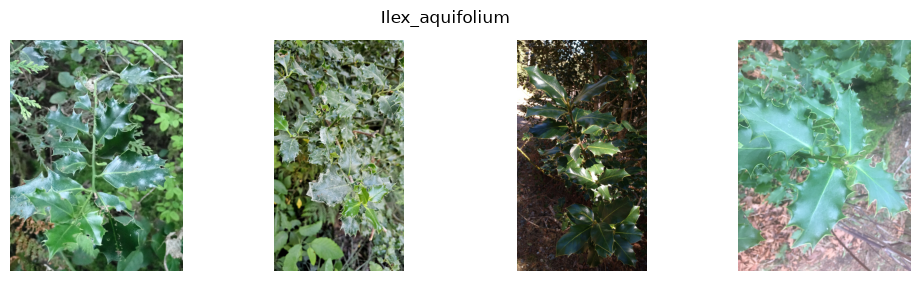

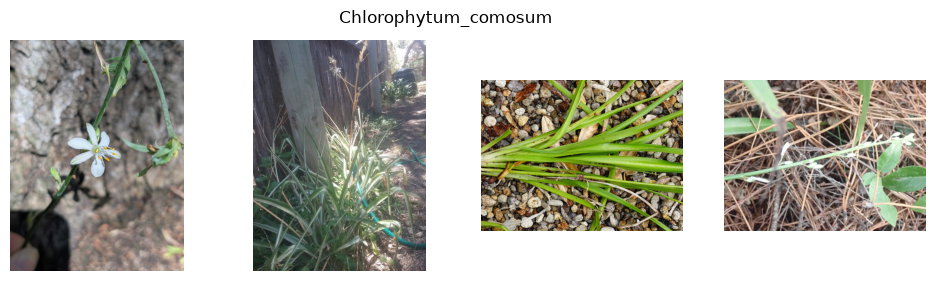

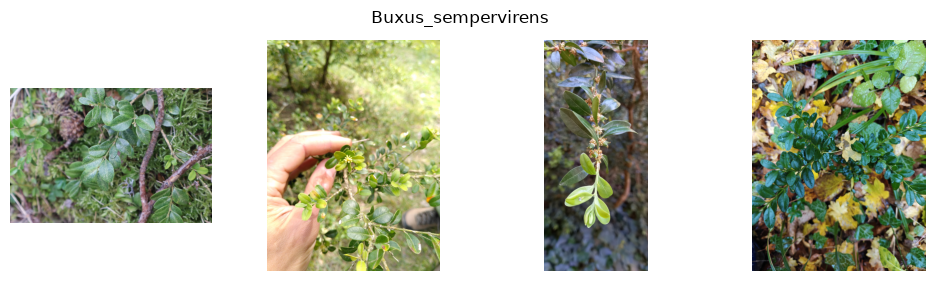

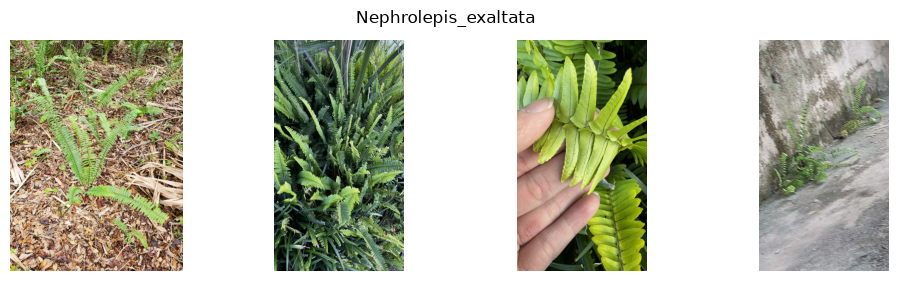

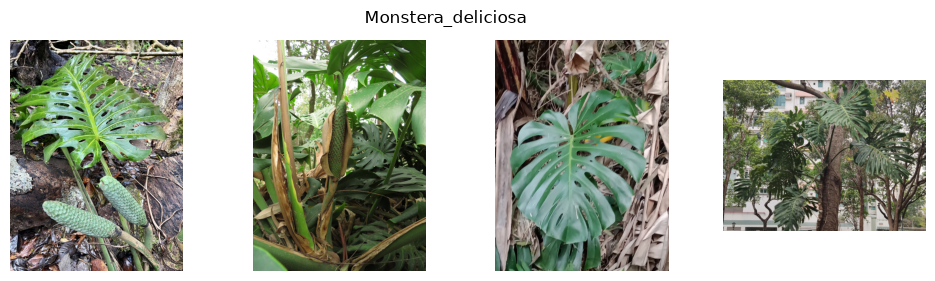

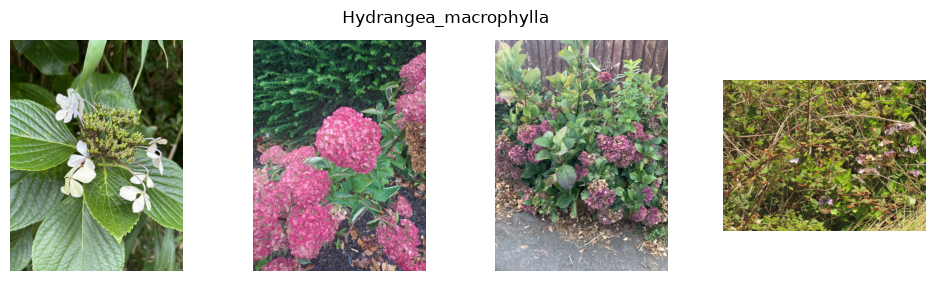

In [11]:
import matplotlib.pyplot as plt

def show_samples(root, n_species=6, per=4):
    dirs = [d for d in Path(root).iterdir() if d.is_dir()]
    for d in random.sample(dirs, min(n_species, len(dirs))):
        files = random.sample(list(d.glob("*.*")), min(per, len(list(d.glob("*.*")))))
        fig, axs = plt.subplots(1, len(files), figsize=(3 * len(files), 3))
        axs = np.atleast_1d(axs)
        for ax, f in zip(axs, files):
            ax.imshow(Image.open(f).convert("RGB")); ax.axis("off")
        fig.suptitle(d.name); plt.show()

show_samples(RAW_ROOT)

## Split data



Stratified 70/15/15 saved to a csv so not overwritten by accident.

Baseline and fine-tuned models both read this file, so they are always compared on identical test images. The manifest is never overwritten unless you pass force=True.

Splits
- 70% train
- 15% validation
- 15% test

In [7]:
from sklearn.model_selection import train_test_split

def build_manifest(root, out_csv, min_per_class=MIN_PER_CLASS, seed=SEED, force=False):
    out_csv = Path(out_csv)
    if out_csv.exists() and not force:
        print("loading existing manifest", out_csv)
        return pd.read_csv(out_csv)
    recs = []
    for d in sorted(Path(root).iterdir()):
        if not d.is_dir():
            continue
        files = [f for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
        if len(files) < min_per_class:
            print(f"dropping {d.name}: only {len(files)} images")
            continue
        recs += [(str(f), d.name) for f in files]
    df = pd.DataFrame(recs, columns=["path", "label"])
    tr, tmp = train_test_split(df.index, test_size=0.30, stratify=df.label, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=df.label[tmp], random_state=seed)
    df["split"] = "train"
    df.loc[va, "split"] = "val"
    df.loc[te, "split"] = "test"
    df.to_csv(out_csv, index=False)
    print(df.split.value_counts().to_dict(), "|", df.label.nunique(), "classes")
    return df

manifest = build_manifest(RAW_ROOT, SPLIT_CSV)

loading existing manifest /Users/zurimckee/plant_project/species_split.csv


## Training
`run_pipeline()` trains the frozen-backbone baseline then fine tunes it.

`evaluate` reports accuracy, macro f1, per class recall, and a confusion matrix, also saves a baseline vs fine tuned comparison table that can be used in the final report.



In [15]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, recall_score
import contextlib\

def amp_ctx():
    return (torch.autocast(device_type="cuda", dtype=torch.float16)
            if use_amp else contextlib.nullcontext())


MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ManifestDS(Dataset):
    def __init__(self, df, class_to_idx, tf):
        self.paths = df.path.tolist()
        self.y = [class_to_idx[l] for l in df.label]
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.y[i]

def make_loaders(df, classes, batch=32):
    c2i = {c: i for i, c in enumerate(classes)}
    mk = lambda split, tf, shuffle, bs: DataLoader(
        ManifestDS(df[df.split == split], c2i, tf), batch_size=bs, shuffle=shuffle, num_workers=0)
    return mk("train", train_tf, True, batch), mk("val", eval_tf, False, 64), mk("test", eval_tf, False, 64)

def build_model(n_classes):
    m = models.resnet50(weights="IMAGENET1K_V2")
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

def set_backbone_trainable(model, flag):
    for name, p in model.named_parameters():
        p.requires_grad = flag or name.startswith("fc.")

def run_epoch(model, dl, opt=None, scaler=None, freeze_bn=False):
    train = opt is not None
    model.train(train)
    if train and freeze_bn:               # truly frozen backbone: keep BatchNorm stats fixed
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    loss_sum, n, ys, ps = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, t in dl:
            x, t = x.to(device), t.to(device)
            with amp_ctx():
                out = model(x)
                loss = nn.functional.cross_entropy(out, t)
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(t); n += len(t)
            ys += t.tolist(); ps += out.argmax(1).tolist()
    acc = float(np.mean(np.array(ys) == np.array(ps)))
    return loss_sum / n, acc, f1_score(ys, ps, average="macro")

def fit(model, train_dl, val_dl, epochs, lr, freeze_backbone):
    set_backbone_trainable(model, not freeze_backbone)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_f1, best_state = -1, None
    for e in range(epochs):
        t0 = time.time()
        tr = run_epoch(model, train_dl, opt, scaler, freeze_bn=freeze_backbone)
        va = run_epoch(model, val_dl)
        sched.step()
        print(f"ep {e+1}/{epochs}  train loss {tr[0]:.3f} acc {tr[1]:.3f} | "
              f"val loss {va[0]:.3f} acc {va[1]:.3f} f1 {va[2]:.3f}  ({time.time()-t0:.0f}s)")
        if va[2] > best_f1:      # choose checkpoint on VALIDATION macro F1, never on test
            best_f1 = va[2]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return best_f1

@torch.no_grad()
def collect_preds(model, dl):
    model.eval()
    ys, ps = [], []
    for x, t in dl:
        with amp_ctx():
            out = model(x.to(device))
        ys += t.tolist(); ps += out.argmax(1).tolist()
    return np.array(ys), np.array(ps)

def evaluate(model, dl, classes, name):
    """Accuracy, macro F1, per-class recall, confusion matrix. Saved to Drive."""
    y, p = collect_preds(model, dl)
    labels = list(range(len(classes)))
    res = {
        "name": name, "n": int(len(y)),
        "accuracy": float((y == p).mean()),
        "macro_f1": float(f1_score(y, p, average="macro", labels=labels, zero_division=0)),
        "per_class_recall": {c: float(r) for c, r in zip(
            classes, recall_score(y, p, labels=labels, average=None, zero_division=0))},
    }
    # healthy-vs-diseased view (only if class names contain 'healthy')
    healthy_idx = {i for i, c in enumerate(classes) if "healthy" in c.lower()}
    if healthy_idx:
        yt = np.array([0 if v in healthy_idx else 1 for v in y])   # 1 = diseased
        yp = np.array([0 if v in healthy_idx else 1 for v in p])
        res["binary_health"] = {"accuracy": float((yt == yp).mean()),
                                "diseased_recall": float(((yt == 1) & (yp == 1)).sum() / max((yt == 1).sum(), 1))}
    json.dump(res, open(RESULTS_DIR / f"{name}.json", "w"), indent=2)
    cm = confusion_matrix(y, p, labels=labels)
    fig, ax = plt.subplots(figsize=(max(6, len(classes) * 0.4),) * 2)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
    fig.tight_layout(); fig.savefig(RESULTS_DIR / f"{name}_confusion.png", dpi=120); plt.show()
    print(f"{name}: acc {res['accuracy']:.3f}  macro-F1 {res['macro_f1']:.3f}  (n={res['n']})")
    if "binary_health" in res:
        print("  healthy-vs-diseased:", res["binary_health"])
    return res

def save_ckpt(model, classes, name):
    torch.save({"model": model.state_dict(), "classes": classes}, CKPT_DIR / f"{name}.pt")

In [13]:
print(manifest.split.value_counts())

split
train    2151
test      461
val       461
Name: count, dtype: int64


## Run frozen backbone baseline -> Then fine-tune it
Run for both species and condition models

The test set is touched once per model, after training. For a dry run on the current 20 species, expect the pipeline to work but don't treat the numbers as final.

loading existing manifest /Users/zurimckee/plant_project/species_split.csv
=== Baseline: frozen ImageNet backbone, train head only ===
ep 1/10  train loss 3.101 acc 0.224 | val loss 2.661 acc 0.373 f1 0.331  (53s)
ep 2/10  train loss 2.393 acc 0.458 | val loss 2.267 acc 0.408 f1 0.372  (53s)
ep 3/10  train loss 2.038 acc 0.525 | val loss 2.055 acc 0.460 f1 0.419  (53s)
ep 4/10  train loss 1.815 acc 0.583 | val loss 1.920 acc 0.508 f1 0.473  (53s)
ep 5/10  train loss 1.668 acc 0.612 | val loss 1.841 acc 0.518 f1 0.481  (53s)
ep 6/10  train loss 1.576 acc 0.634 | val loss 1.786 acc 0.523 f1 0.490  (53s)
ep 7/10  train loss 1.512 acc 0.656 | val loss 1.750 acc 0.531 f1 0.500  (53s)
ep 8/10  train loss 1.464 acc 0.679 | val loss 1.731 acc 0.540 f1 0.516  (53s)
ep 9/10  train loss 1.442 acc 0.679 | val loss 1.724 acc 0.544 f1 0.522  (53s)
ep 10/10  train loss 1.430 acc 0.681 | val loss 1.722 acc 0.544 f1 0.522  (53s)


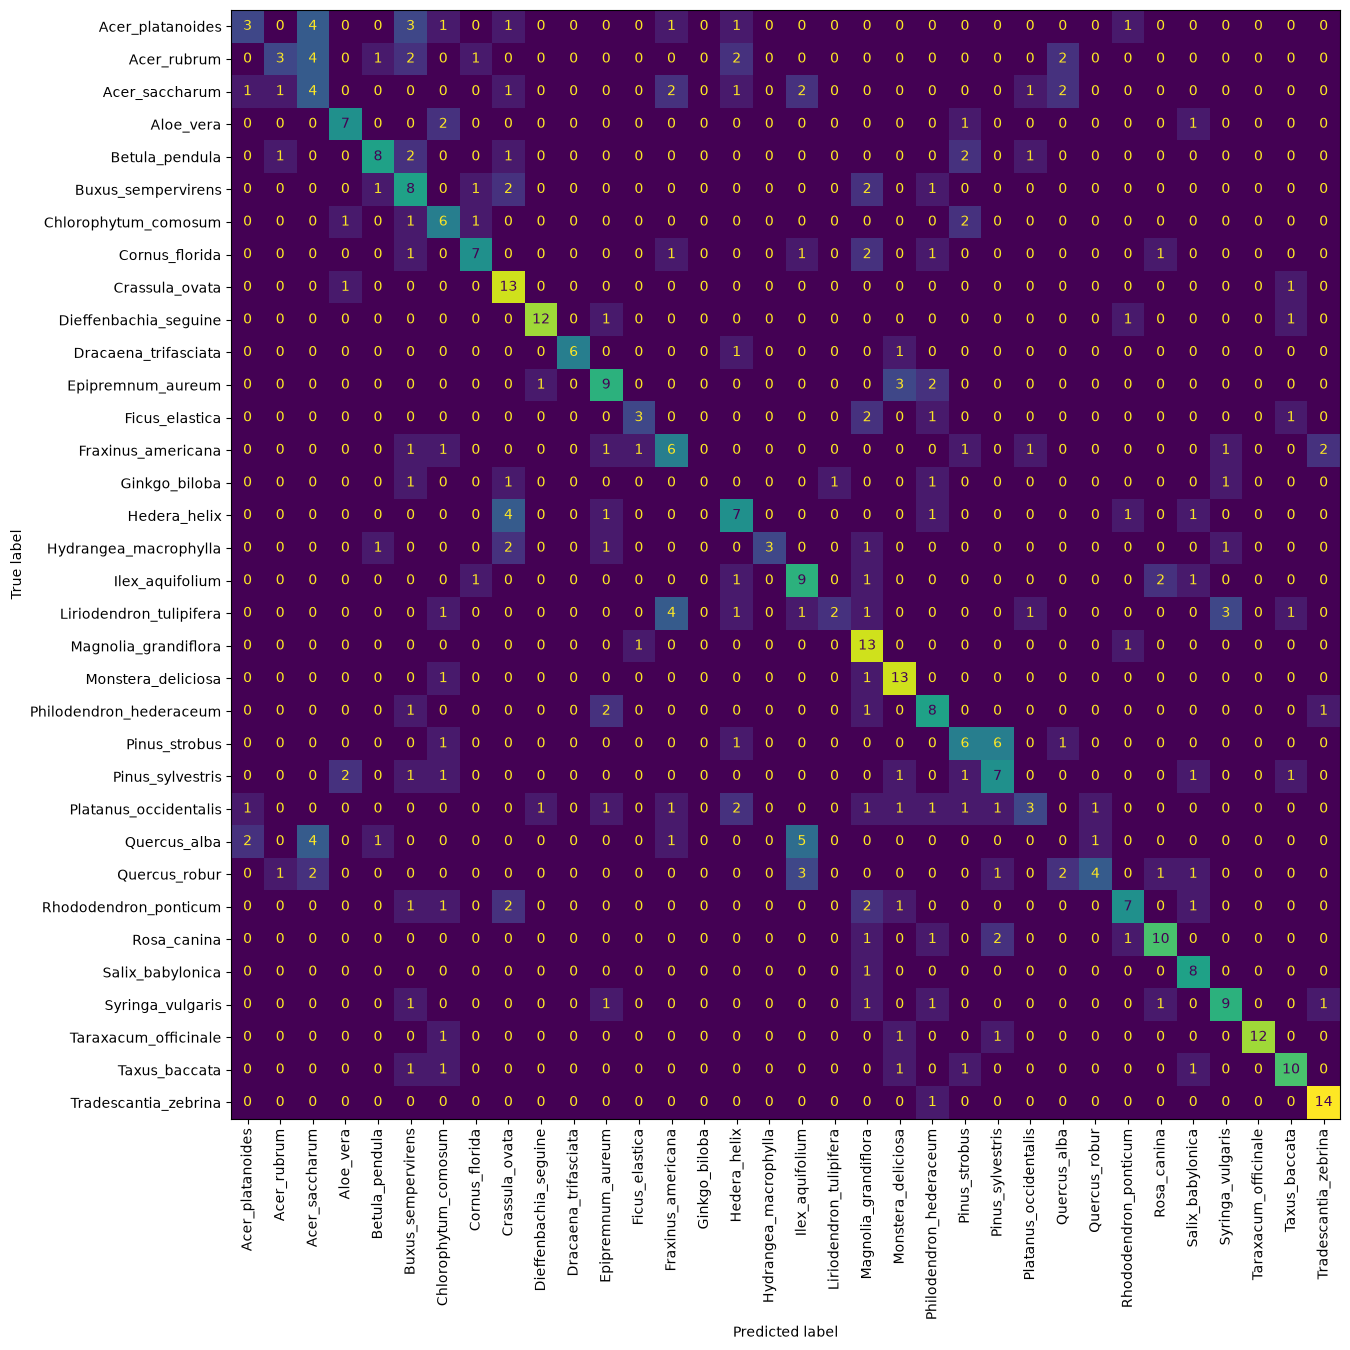

species_baseline_test: acc 0.521  macro-F1 0.499  (n=461)
=== Fine-tune: unfreeze everything, low LR ===
ep 1/10  train loss 1.854 acc 0.504 | val loss 1.457 acc 0.575 f1 0.563  (88s)
ep 2/10  train loss 1.086 acc 0.690 | val loss 1.237 acc 0.646 f1 0.638  (95s)
ep 3/10  train loss 0.773 acc 0.783 | val loss 1.096 acc 0.679 f1 0.681  (99s)
ep 4/10  train loss 0.553 acc 0.853 | val loss 1.065 acc 0.698 f1 0.698  (101s)
ep 5/10  train loss 0.412 acc 0.888 | val loss 1.017 acc 0.701 f1 0.695  (102s)
ep 6/10  train loss 0.337 acc 0.918 | val loss 1.014 acc 0.709 f1 0.709  (134s)
ep 7/10  train loss 0.265 acc 0.939 | val loss 0.988 acc 0.720 f1 0.716  (144s)
ep 8/10  train loss 0.228 acc 0.943 | val loss 0.988 acc 0.722 f1 0.719  (122s)
ep 9/10  train loss 0.215 acc 0.947 | val loss 0.986 acc 0.718 f1 0.714  (104s)
ep 10/10  train loss 0.193 acc 0.960 | val loss 0.990 acc 0.718 f1 0.717  (105s)


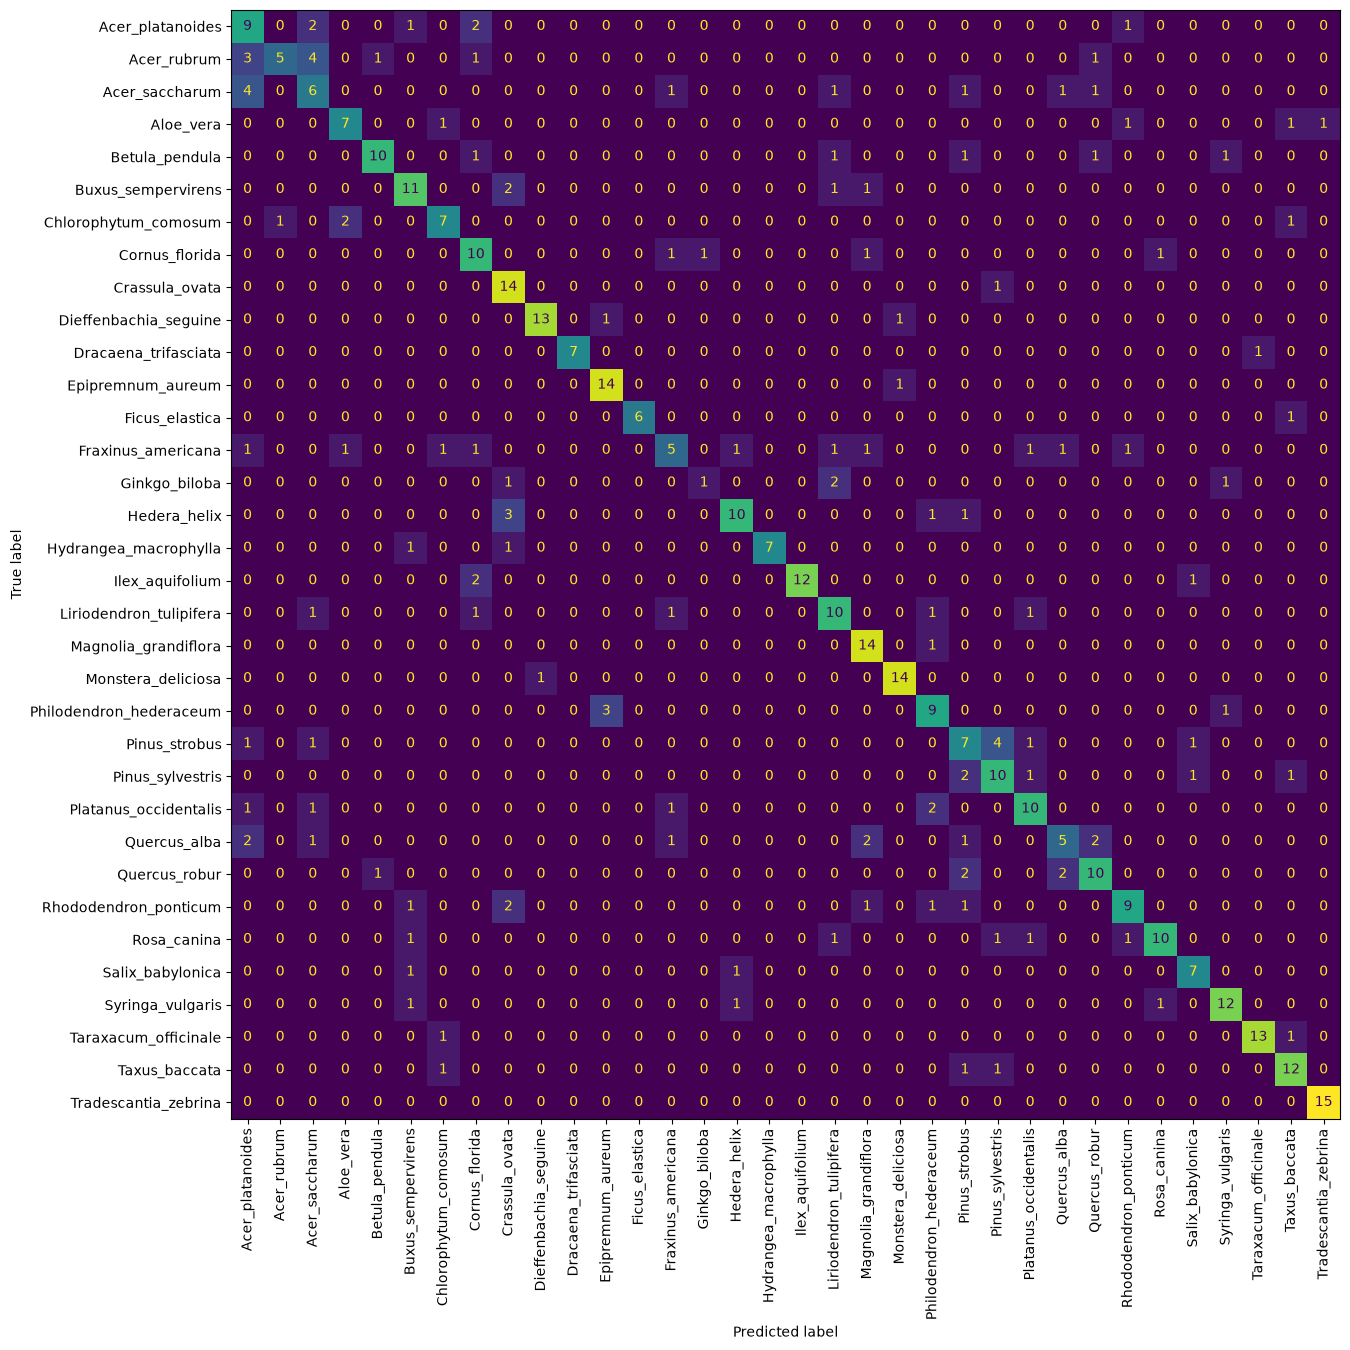

species_finetuned_test: acc 0.696  macro-F1 0.693  (n=461)
            model  accuracy  macro_f1
baseline (frozen)  0.520607  0.498707
       fine-tuned  0.696312  0.692887


In [14]:


def run_pipeline(root, tag, csv_path, head_epochs=10, ft_epochs=10, batch=32):
    df = build_manifest(root, csv_path)
    classes = sorted(df.label.unique())
    train_dl, val_dl, test_dl = make_loaders(df, classes, batch)
    model = build_model(len(classes)).to(device)

    print("=== Baseline: frozen ImageNet backbone, train head only ===")
    fit(model, train_dl, val_dl, head_epochs, lr=1e-3, freeze_backbone=True)
    save_ckpt(model, classes, f"{tag}_baseline")
    base = evaluate(model, test_dl, classes, f"{tag}_baseline_test")

    print("=== Fine-tune: unfreeze everything, low LR ===")
    fit(model, train_dl, val_dl, ft_epochs, lr=1e-4, freeze_backbone=False)
    save_ckpt(model, classes, f"{tag}_finetuned")
    ft = evaluate(model, test_dl, classes, f"{tag}_finetuned_test")

    table = pd.DataFrame([{"model": "baseline (frozen)", "accuracy": base["accuracy"], "macro_f1": base["macro_f1"]},
                          {"model": "fine-tuned", "accuracy": ft["accuracy"], "macro_f1": ft["macro_f1"]}])
    print(table.to_string(index=False))
    table.to_csv(RESULTS_DIR / f"{tag}_comparison.csv", index=False)
    return model, classes

species_model, species_classes = run_pipeline(RAW_ROOT, "species", SPLIT_CSV)

## Analysis post-training
per-class table, top confusions, and top-3 accuracy
also shows whether the weakest classes are also the ones with the fewest training images.

In [16]:
test_df = manifest[manifest.split == "test"].reset_index(drop=True)
c2i = {c: i for i, c in enumerate(species_classes)}
test_dl = DataLoader(ManifestDS(test_df, c2i, eval_tf), batch_size=64, num_workers=0)

@torch.no_grad()
def predict_probs(model, dl):
    model.eval()
    out = []
    for x, _ in dl:
        out.append(torch.softmax(model(x.to(device)).float(), 1).cpu())
    return torch.cat(out).numpy()

probs = predict_probs(species_model, test_dl)
y = test_df.label.map(c2i).values
pred = probs.argmax(1)
test_df["pred"] = [species_classes[i] for i in pred]
test_df["conf"] = probs.max(1)
test_df["correct"] = test_df.label == test_df.pred

top3 = np.argsort(-probs, axis=1)[:, :3]
print(f"top-1 acc: {test_df.correct.mean():.3f}   top-3 acc: {np.mean([y[i] in top3[i] for i in range(len(y))]):.3f}")

rows = []
for c in species_classes:
    sub = test_df[test_df.label == c]
    wrong = sub[~sub.correct]
    rows.append({
        "class": c,
        "train_n": int(((manifest.split == "train") & (manifest.label == c)).sum()),
        "test_n": len(sub),
        "recall": round(sub.correct.mean(), 2),
        "most_confused_with": ", ".join(f"{k} ({v})" for k, v in wrong.pred.value_counts().head(2).items()),
    })
per_class = pd.DataFrame(rows).sort_values("recall")
print("\nWorst 12 classes:")
print(per_class.head(12).to_string(index=False))

print("\nMost common mistakes (true -> predicted):")
print(test_df[~test_df.correct].groupby(["label", "pred"]).size()
      .sort_values(ascending=False).head(12).to_string())

top-1 acc: 0.696   top-3 acc: 0.844

Worst 12 classes:
                class  train_n  test_n  recall                                  most_confused_with
        Ginkgo_biloba       25       5    0.20     Liriodendron_tulipifera (2), Crassula_ovata (1)
          Acer_rubrum       70      15    0.33            Acer_saccharum (4), Acer_platanoides (3)
   Fraxinus_americana       70      15    0.33       Rhododendron_ponticum (1), Cornus_florida (1)
         Quercus_alba       68      14    0.36      Magnolia_grandiflora (2), Acer_platanoides (2)
       Acer_saccharum       70      15    0.40             Acer_platanoides (4), Quercus_robur (1)
        Pinus_strobus       70      15    0.47            Pinus_sylvestris (4), Acer_saccharum (1)
     Acer_platanoides       70      15    0.60              Acer_saccharum (2), Cornus_florida (2)
Rhododendron_ponticum       70      15    0.60          Crassula_ovata (2), Buxus_sempervirens (1)
 Chlorophytum_comosum       50      11    0.64        

## Image grid helper
misclassified test images - shows the most confident mistakes first

In [23]:
import re
from IPython.display import display

def show_grid(df_rows, title, cols=4):
    if len(df_rows) == 0:
        print("no images for", title); return
    n = len(df_rows)
    r = (n + cols - 1) // cols
    fig, axs = plt.subplots(r, cols, figsize=(3.2 * cols, 3.5 * r))
    axs = np.array(axs).reshape(-1)
    for ax in axs:
        ax.axis("off")
    for ax, (_, row) in zip(axs, df_rows.iterrows()):
        ax.imshow(Image.open(row.path).convert("RGB"))
        cap = f"true: {row.label}"
        if "pred" in row and isinstance(row.pred, str):
            cap += f"\npred: {row.pred} ({row.conf:.2f})"
        ax.set_title(cap, fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    fname = re.sub(r"[^A-Za-z0-9_]+", "_", title)[:80]
    out = RESULTS_DIR / f"grid_{fname}.png"
    fig.savefig(out, dpi=100)
    display(fig)
    plt.close(fig)
    print("saved:", out)

## Predict function
For interface team
Loads a saved checkpoint and returns the top-k species with confidence.

In [19]:
def load_model(ckpt_name):
    ck = torch.load(CKPT_DIR / f"{ckpt_name}.pt", map_location=device)
    m = build_model(len(ck["classes"]))
    m.load_state_dict(ck["model"]); m.to(device).eval()
    return m, ck["classes"]

@torch.no_grad()
def predict(img, model, classes, k=3):
    """img: file path or PIL image."""
    if not isinstance(img, Image.Image):
        img = Image.open(img)
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    probs = torch.softmax(model(x), 1)[0]
    top = probs.topk(min(k, len(classes)))
    return {"prediction": classes[top.indices[0].item()],
            "confidence": float(top.values[0]),
            "top_k": [(classes[i], float(p)) for p, i in zip(top.values.tolist(), top.indices.tolist())]}

# example (uncomment): print(predict("/content/some_photo.jpg", species_model, species_classes))

## Phone-photo test set (use once labels exist)

Put the phone photos in a folder on Drive and make a CSV with columns `filename,label` where `label` exactly matches a training class name (e.g. `Monstera_deliciosa`). This reports metrics on real-world images.
!Do not train or tune on this set.!

In [ ]:
PHONE_DIR = BASE / "phone_photos"
PHONE_CSV = BASE / "phone_labels.csv"      # columns: filename,label

def evaluate_phone_set(model, classes, name):
    lab = pd.read_csv(PHONE_CSV)
    lab["path"] = lab.filename.map(lambda f: str(PHONE_DIR / f))
    unknown = set(lab.label) - set(classes)
    if unknown:
        print("labels not in training classes (excluded):", unknown)
    lab = lab[lab.label.isin(classes)].reset_index(drop=True)
    c2i = {c: i for i, c in enumerate(classes)}
    dl = DataLoader(ManifestDS(lab, c2i, eval_tf), batch_size=32, num_workers=0)
    return evaluate(model, dl, classes, f"{name}_phone")

# when ready: evaluate_phone_set(species_model, species_classes, "species_finetuned")

## Condition/Health model and care advice

Put a labeled health dataset on Drive in folder-per-class layout (e.g. healthy, yellowing, spots, or PlantVillage-style Tomato___Late_blight) and run the same pipeline. If any class name contains "healthy", evaluate also reports the healthy-vs-diseased accuracy and diseased recall automatically.

TODO: Figure out what the health labels are going to be (consult team)

In [ ]:
CONDITION_ROOT = Path("/content/drive/MyDrive/plant_health")   # folder-per-class, once the dataset is chosen
# condition_model, condition_classes = run_pipeline(CONDITION_ROOT, "condition", BASE / "condition_split.csv")

In [ ]:
# Care-advice lookup: deterministic, so advice always matches the predicted condition.
# Keys must match the health class names exactly. Placeholder text: have a teammate fill in real guidance.
CARE_ADVICE = {
    "healthy": "No problems detected. Keep your current watering and light routine.",
    "yellowing": "TODO: check for overwatering, poor drainage or nutrient deficiency.",
    "brown_tips": "TODO: check for low humidity, underwatering or fertilizer buildup.",
    "spots": "TODO: check for fungal or bacterial leaf spot; remove affected leaves, avoid wetting foliage.",
    "wilting": "TODO: check soil moisture and roots.",
}
def get_advice(condition_label):
    return CARE_ADVICE.get(condition_label, "No advice available for this condition yet.")